<a href="https://colab.research.google.com/github/Alex-Iatrop/ISLP_projects/blob/master/assigment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

items = pd.read_csv("items/items.csv")
rated = pd.read_csv("items/items_rated.csv")

In [ ]:
items

,id,text,rating,label,evidence
0,1,Leaving out the fact that they are flying in i...,NaN,NaN,NaN
1,2,I'm white so no pudding for you Mr.Trump Unive...,NaN,NaN,NaN
2,3,"... stupid people are a fact of life, just loo...",NaN,NaN,NaN
3,4,"No, not in 'other' words, in precisely the wor...",NaN,NaN,NaN
4,5,"An ""atheist""?, now it's even more stupid since...",NaN,NaN,NaN
5,6,"So much for civility, Roy's vitriol is the sam...",NaN,NaN,NaN
6,7,"Thanks Bob, but according to Ted Baker I was w...",NaN,NaN,NaN
7,8,Julian should receive the Gold Star award from...,NaN,NaN,NaN
8,9,"Where's the outrage, klastri, homer, keaukaha,...",NaN,NaN,NaN
9,10,It williams be interesting if this starts a fu...,NaN,NaN,NaN


In [ ]:
rated

,id,text,rating,label,evidence
0,1,Leaving out the fact that they are flying in i...,1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump Unive...,2,civil,not needed
2,3,"... stupid people are a fact of life, just loo...",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the wor...",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since...",4,toxic,it's even more stupid || IMUA!!!
5,6,"So much for civility, Roy's vitriol is the sam...",2,civil,not needed
6,7,"Thanks Bob, but according to Ted Baker I was w...",3,toxic,but according to Ted Baker I was writing barra...
7,8,Julian should receive the Gold Star award from...,3,toxic,I hope he rots.
8,9,"Where's the outrage, klastri, homer, keaukaha,...",3,toxic,"Hypocrites, liars, Bigots, racist, sexists, LOL"
9,10,It williams be interesting if this starts a fu...,4,toxic,quite a few pigs at the trough!


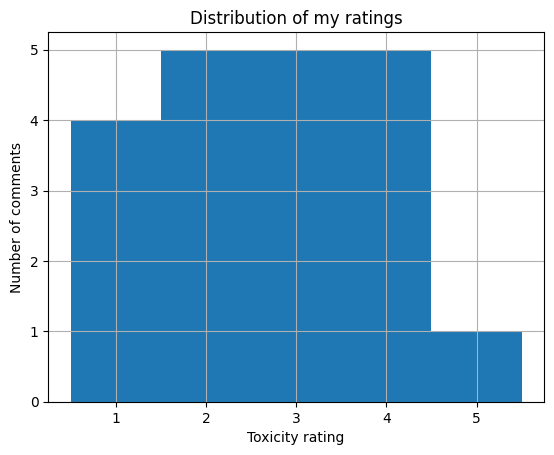

In [ ]:
import matplotlib.pyplot as plt

rated["rating"].hist(bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5])
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Toxicity rating")
plt.ylabel("Number of comments")
plt.title("Distribution of my ratings")
plt.show()

For the generation of this graph I have chosen the above historgram which gathers the data of my ratings and puts them into bins of size 1. I want the centers of each rating to be at the center of the bin. Thus I have chosen the bins to start from 0.5-1.5 etc. The graph shows how I have rated the comments randomly chosen by the the items.csv. Most ratings are between 2 and 4 while I rarely selected 5. The distribution seems to be slightly right skewed, but more data is needed to draw any final conclusions.

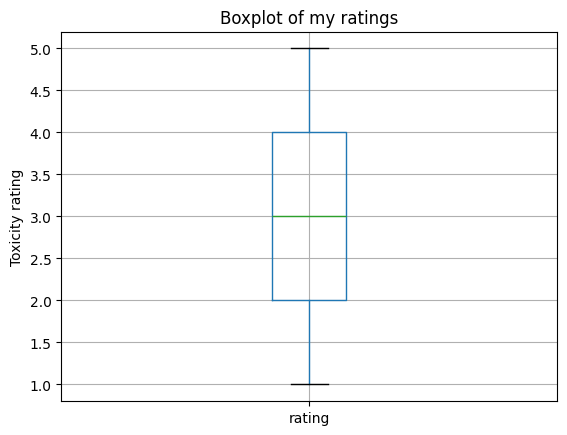

In [ ]:
rated.boxplot(column="rating")
plt.ylabel("Toxicity rating")
plt.title("Boxplot of my ratings")
plt.show()

The box plot provides a summary of my ratings. We can observe that the IQR is between 2-4 ratings, that is, the 50% of the data are gathered between the two values. The slight skweness is not clearly visible here, and we cannot draw any conclusions due to the size of the sample.

In [ ]:
rated["rating"].value_counts().sort_index()

rating
1    4
2    5
3    5
4    5
5    1
Name: count, dtype: int64

In [3]:
print("Number of items:", len(items))
print("Number of ratings:", len(rated))

Number of items: 20
Number of ratings: 20


In [4]:
!pip install -q syndisco

In [6]:
import json                 # to save the conversations
import random               # to choose random participants
import re                   # to find the rating in the model's answer

import pandas as pd         # for the tables
import torch                # the library that runs the model
import syndisco             # the library of this lab

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


In [11]:
texts = dict(zip(items["id"], items["text"]))

In [7]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
    name="qwen",
    max_out_tokens=80,
    generation_kwargs={"repetition_penalty": 1.1}
)

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

In [8]:
print(model)

In [9]:
# a small pool of made-up people: each is just a dictionary of attributes
PERSONAS = [
    {"username": "Maria_K", "age": 38, "job": "nurse", "personality": ["patient", "direct"]},
    {"username": "Giannis", "age": 21, "job": "game developer", "personality": ["sarcastic", "curious"]},
    {"username": "Kimya", "age": 67, "job": "retired teacher", "personality": ["strict", "grumpy"]},
    {"username": "Tom_77", "age": 45, "job": "truck driver", "personality": ["blunt", "funny"]},
    {"username": "Sofia", "age": 29, "job": "journalist", "personality": ["skeptical", "polite"]},
]

# the same context and instructions for every participant
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not refuse, "
    "do not mention that you are an AI, and never answer with an apology or a refusal."
)

In [12]:
import random

rng = random.Random(0)

# We chose the first commnet from the texts
first_id = next(iter(texts))
first_text = texts[first_id]

# we chose the first 3 participants
users = []
for persona in rng.sample(PERSONAS, 3):
    user = syndisco.Actor(
        model=model,
        persona=persona,
        context=CONTEXT,
        instructions=INSTRUCTIONS,
        name=persona["username"]
    )
    users.append(user)

discussion = syndisco.Discussion(
    next_turn_manager=syndisco.RandomTurnManager(users),
    users=users,
    conv_len=4,
    seed_opinions=[first_text],
    seed_opinion_usernames=["OriginalPoster"]
)

discussion.begin(verbose=False)

/usr/local/lib/python3.13/dist-packages/syndisco/turn_manager.py:163: UserWarning: 
                p_respond has been set to 0, which disables responding
                altogether. In that case, it may be better to use the
                RandomTurnManager class instead.
                
  warnings.warn(


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

In [13]:
for entry in discussion.get_logs():
    print(entry["name"], ":", entry["text"], "\n")

OriginalPoster : Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information. 

Maria_K : It's true that their flight path through international airspace matters, but focusing solely on that misses the bigger picture of safety concerns. 

Tom_77 : "Agreed, leaving out context like the flight path through international airspace does make it harder to see the full story, but safety should definitely be at the forefront." 

Sofia : "Absolutely, highlighting the flight path through international airspace is important, but ensuring passenger safety remains paramount." 

Tom_77 : "Exactly! Safety must always be the top priority, but it’s also crucial to provide a complete picture." 

